# DSCI 552: Homework 6

Name: Hanwen Zhang  
GitHub Username: zhw123456789  
USC ID: 4602764147

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.precision", 5)
pd.set_option("display.max_rows", 180)

## 1(a) APS Failure data

[UCI APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks).
The supplied training and test sets are kept separate. Positive means an APS-related failure.

In [2]:
train_data = pd.read_csv("../data/aps_failure_training_set.csv.gz", skiprows=20,
                         na_values="na")
test_data = pd.read_csv("../data/aps_failure_test_set.csv.gz", skiprows=20,
                        na_values="na")
X_train = train_data.drop(columns="class")
X_test = test_data.drop(columns="class")
y_train = train_data["class"].map({"neg": 0, "pos": 1})
y_test = test_data["class"].map({"neg": 0, "pos": 1})
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (60000, 170)
Test shape: (16000, 170)


## 1(b)(i) Missing values

Common methods include mean or median replacement, nearest-neighbor imputation, and iterative regression imputation. I use medians because these measurements are skewed. The imputer is fitted on training rows and reused for test rows; during CV it is fitted within each training fold.
[Imputation methods](https://scikit-learn.org/stable/modules/impute.html).

In [3]:
imputer = SimpleImputer(strategy="median")
train_filled = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
test_filled = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)
print("Missing training values:", X_train.isna().sum().sum())
print("Missing test values:", X_test.isna().sum().sum())

Missing training values: 850015
Missing test values: 228680


## 1(b)(ii) Coefficient of variation

CV = sample standard deviation / sample mean, using imputed training data.

In [4]:
feature_cv = train_filled.std(ddof=1) / train_filled.mean()
blocks = [feature_cv.iloc[i:i + 60].rename_axis("Feature").reset_index(name="CV")
          for i in range(0, len(feature_cv), 60)]
display(pd.concat(blocks, axis=1).fillna(""))

,Feature,CV,Feature,CV,Feature,CV
0,aa_000,2.45094,ba_008,6.83066,cs_007,5.42488
1,ab_000,10.38349,ba_009,9.43024,cs_008,48.10221
2,ac_000,2.31024,bb_000,2.40520,cs_009,237.93055
3,ad_000,244.32282,bc_000,7.26445,ct_000,7.84999
4,ae_000,24.20014,bd_000,5.35216,cu_000,6.67286
5,af_000,19.47130,be_000,6.84718,cv_000,1.83721
6,ag_000,92.91776,bf_000,7.45354,cx_000,4.74851
7,ag_001,35.24931,bg_000,2.30931,cy_000,36.60091
8,ag_002,17.56591,bh_000,2.62872,cz_000,14.50559
9,ag_003,8.64740,bi_000,3.02203,da_000,29.36753


## 1(b)(iii) Correlation matrix

cd_000 is constant in the training set, so its correlations are undefined (blank cells).

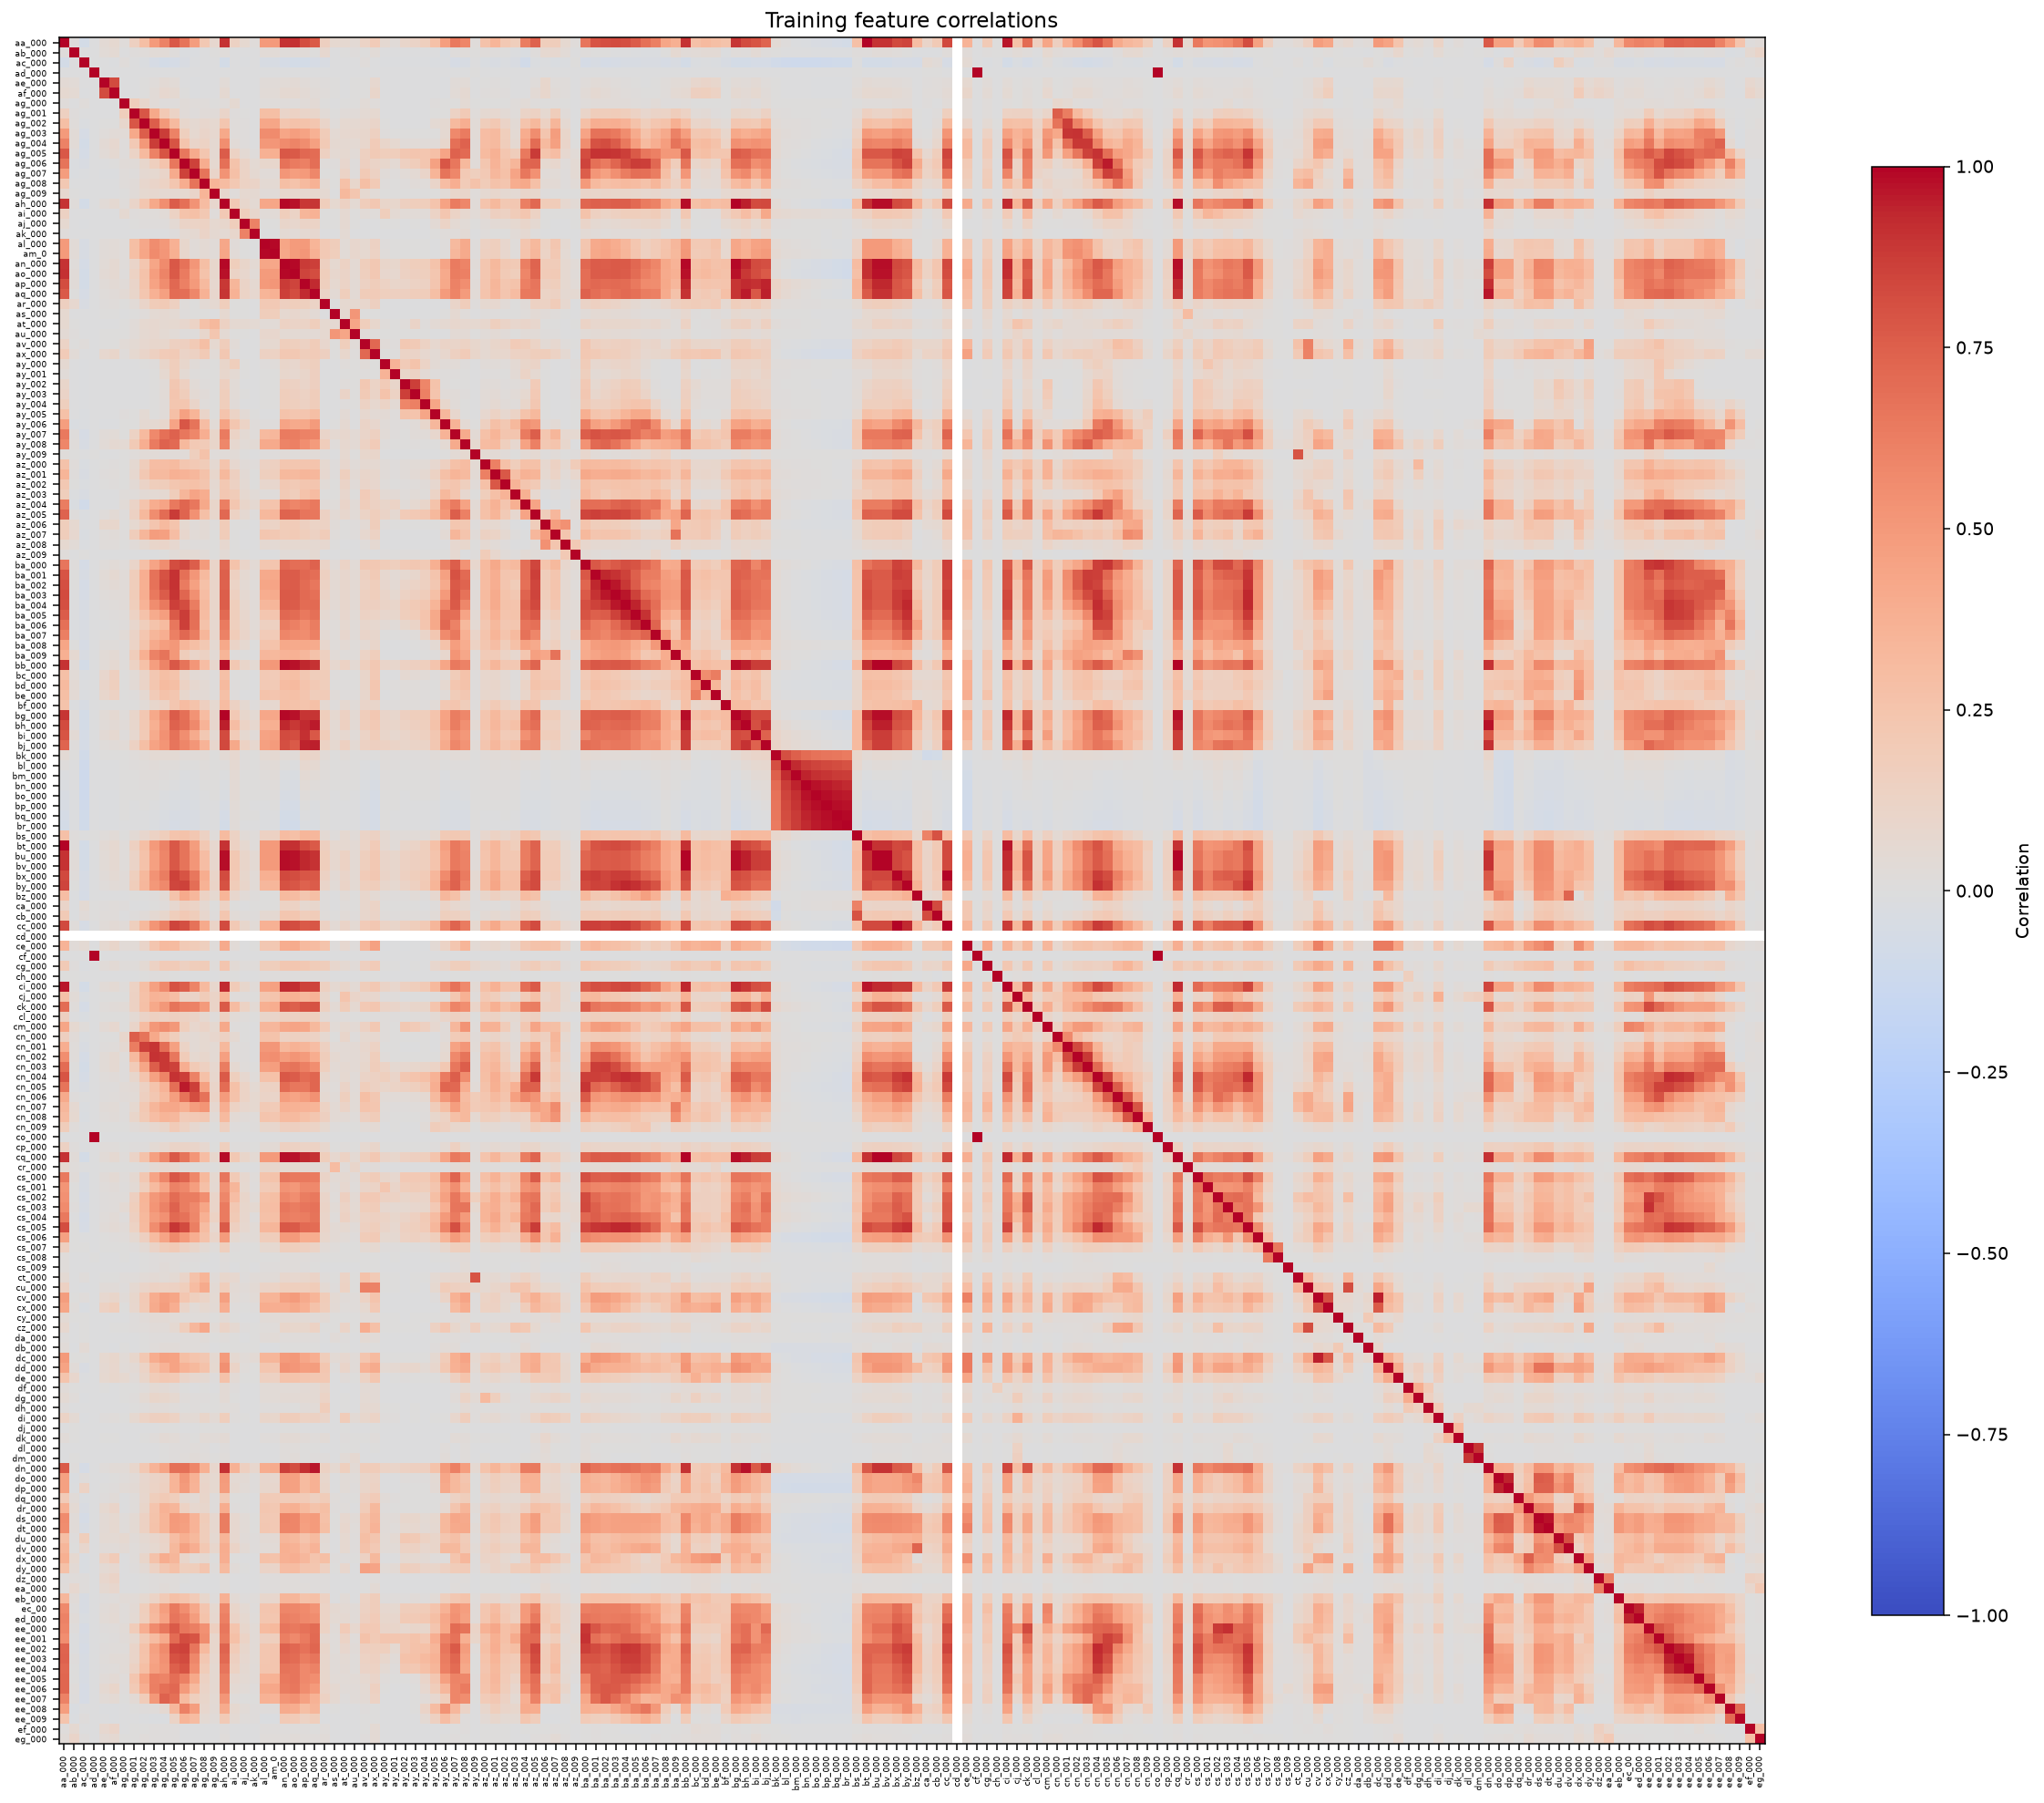

In [5]:
correlation = train_filled.corr()
fig, ax = plt.subplots(figsize=(18, 16))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(170), correlation.columns, rotation=90, fontsize=5)
ax.set_yticks(range(170), correlation.index, fontsize=5)
ax.set_title("Training feature correlations")
fig.colorbar(image, ax=ax, shrink=0.75, label="Correlation")
fig.tight_layout()
plt.show()

## 1(b)(iv) Features with the highest CV

floor(sqrt(170)) = 13. Scatter plots use slight vertical jitter for the binary labels. Symlog axes keep large values visible while retaining zeros. All 170 predictors are used in the models.

,CV
cf_000,244.88752
co_000,244.50739
ad_000,244.32282
cs_009,237.93055
dh_000,123.21610
dj_000,117.49423
ag_000,92.91776
as_000,87.33250
ay_009,84.73373
ak_000,80.42498


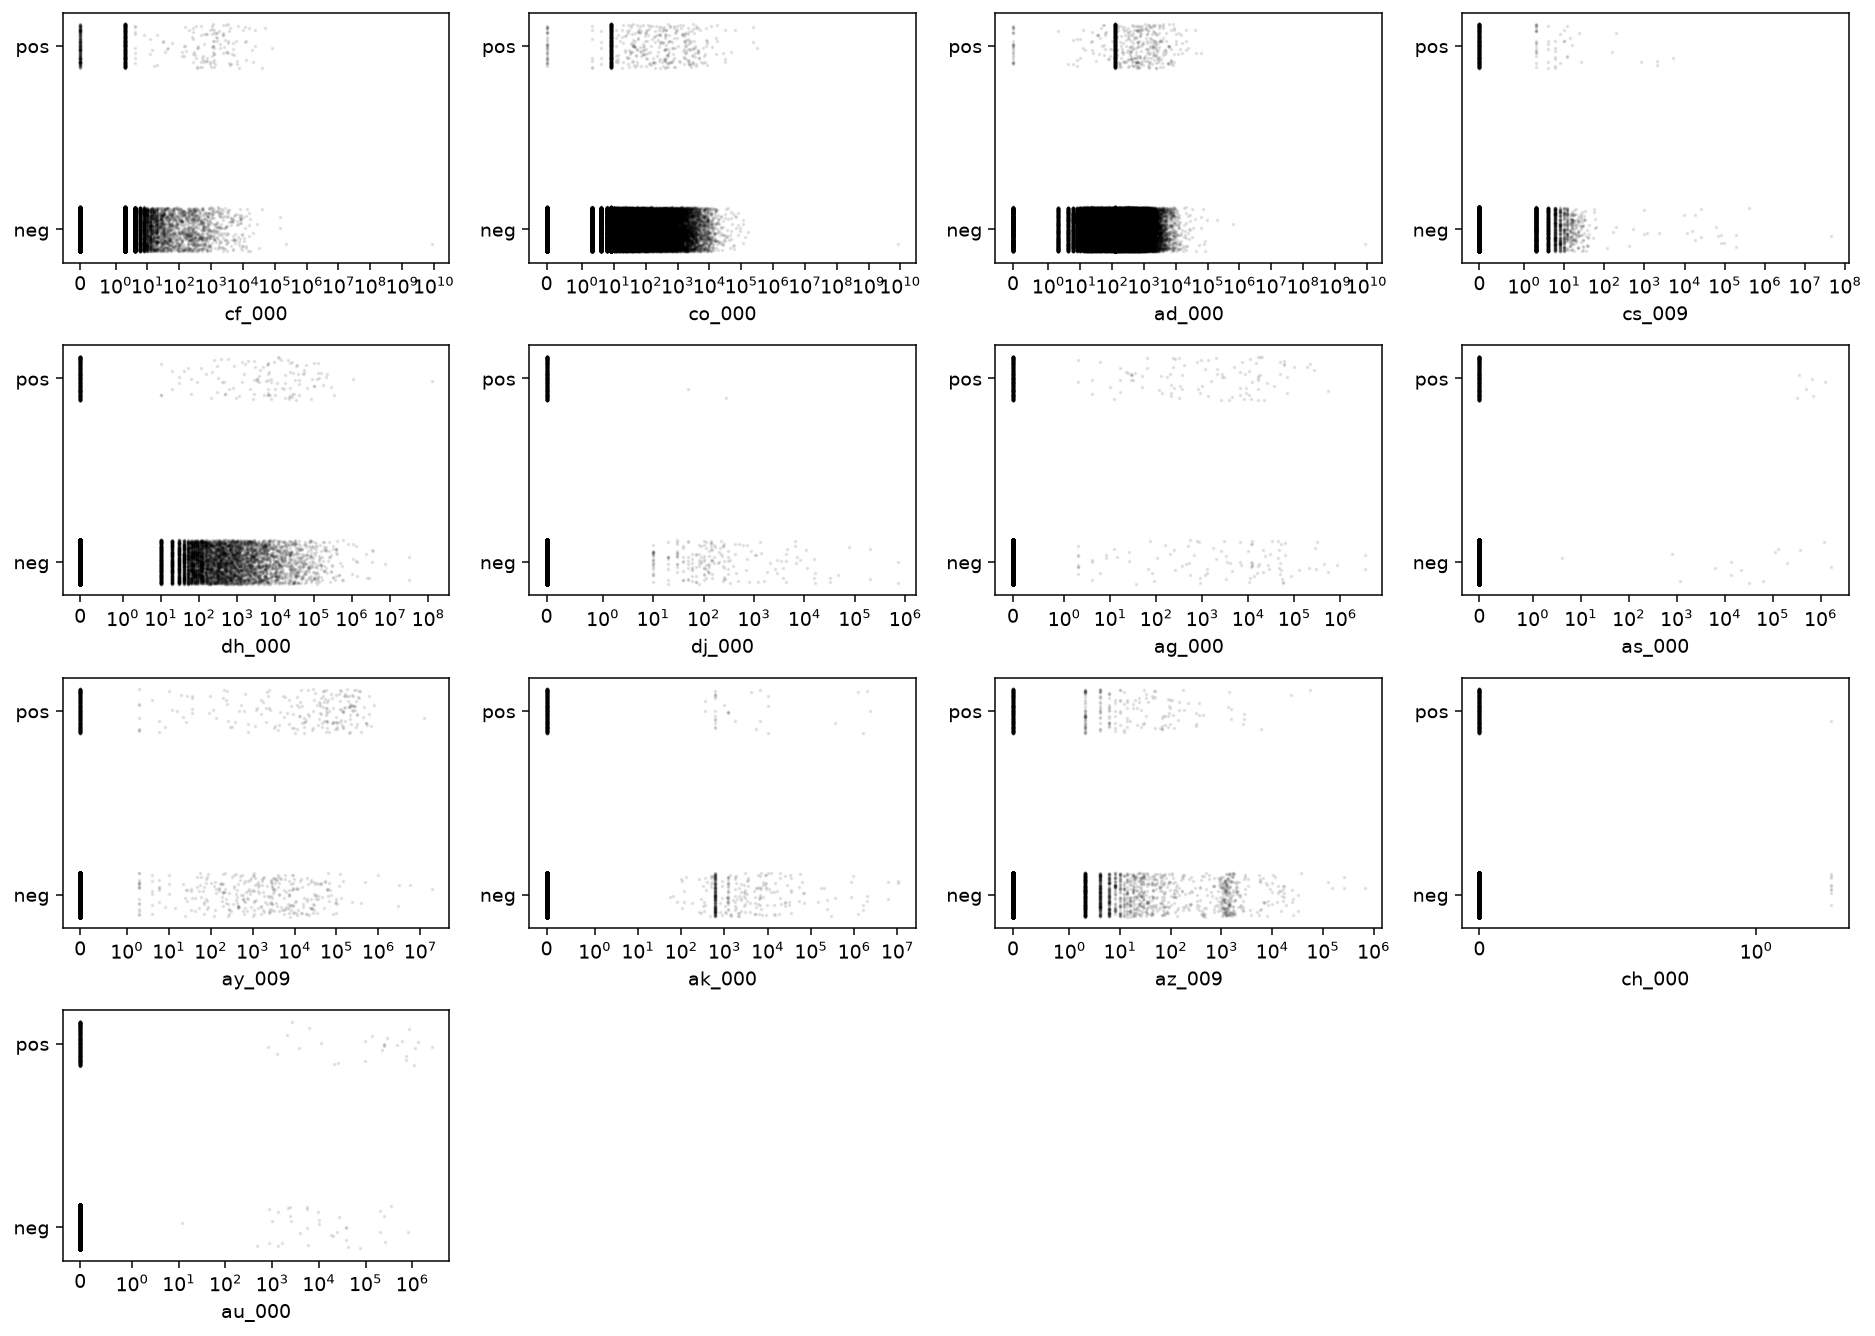

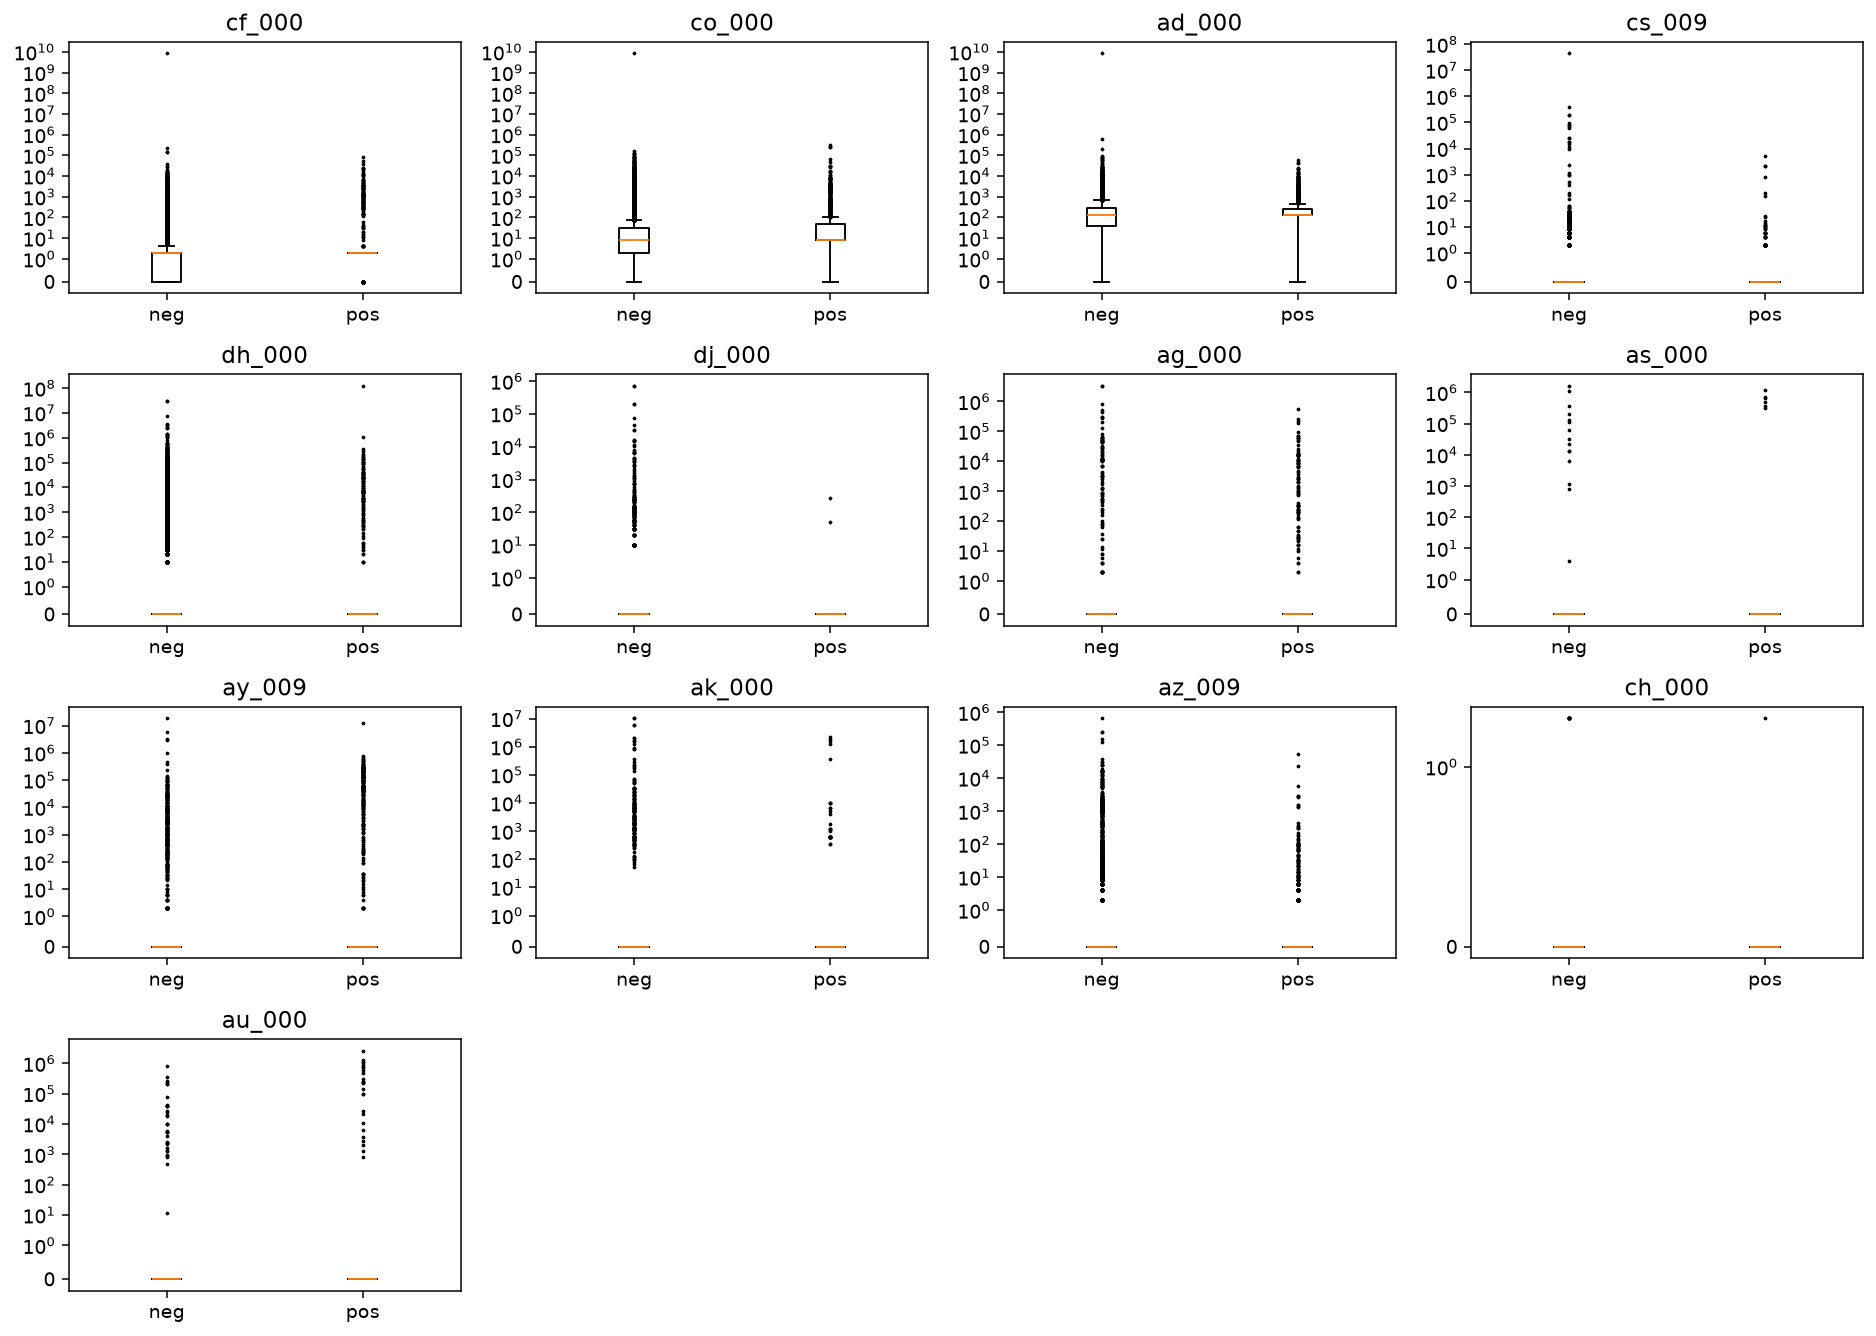

In [6]:
top_features = feature_cv.nlargest(int(np.sqrt(170))).index
display(feature_cv.loc[top_features].to_frame("CV"))

jitter = y_train.to_numpy() + np.random.default_rng(552).uniform(-0.12, 0.12, len(y_train))
fig, axes = plt.subplots(4, 4, figsize=(14, 10))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(train_filled[feature], jitter, s=1, alpha=0.08, color="black")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xlabel(feature)
    ax.set_yticks([0, 1], ["neg", "pos"])
for ax in axes.flat[len(top_features):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(14, 10))
for ax, feature in zip(axes.flat, top_features):
    groups = [train_filled.loc[y_train == label, feature] for label in [0, 1]]
    ax.boxplot(groups, tick_labels=["neg", "pos"], flierprops={"markersize": 1})
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(feature)
for ax in axes.flat[len(top_features):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

The plots suggest differences between the classes, but do not establish statistical significance. High CV means high relative variability, not necessarily strong predictive value.

## 1(b)(v) Class balance

In [7]:
class_counts = pd.DataFrame({"Train": y_train.value_counts(),
                             "Test": y_test.value_counts()}).rename(index={0: "neg", 1: "pos"})
display(class_counts)
print("Training negative-to-positive ratio:", round((y_train == 0).sum() / y_train.sum(), 2))

,Train,Test
class,,
neg,59000,15625
pos,1000,375


Training negative-to-positive ratio: 59.0


Only 1,000 of 60,000 training rows are positive (1.67%), giving a 59:1 ratio. The data are highly imbalanced.

## 1(c) Random forest without compensation

Confusion matrices use actual classes as rows and predicted classes as columns. Classification uses a probability threshold of 0.5.

Pred neg  Pred pos
Set   Actual                    
Train neg        59000         0
      pos            0      1000
Test  neg        15606        19
      pos          102       273

,Error,AUC,Positive recall
Set,,,
Train,0.00000,1.00000,1.000
Test,0.00756,0.99439,0.728


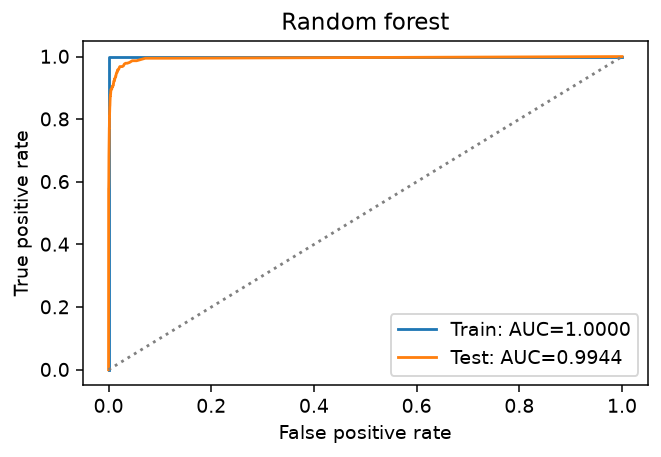

OOB error: 0.0058


In [8]:
def report_model(model, train_X, test_X, name):
    rows = []
    matrices = {}
    fig, ax = plt.subplots(figsize=(5, 3.5))
    for split, X, y in [("Train", train_X, y_train), ("Test", test_X, y_test)]:
        probability = model.predict_proba(X)[:, 1]
        prediction = model.predict(X)
        matrix = confusion_matrix(y, prediction, labels=[0, 1])
        matrices[split] = pd.DataFrame(matrix, index=["neg", "pos"],
                                       columns=["Pred neg", "Pred pos"])
        auc = roc_auc_score(y, probability)
        rows.append([split, 1 - accuracy_score(y, prediction), auc,
                     matrix[1, 1] / matrix[1].sum()])
        fpr, tpr, _ = roc_curve(y, probability)
        ax.plot(fpr, tpr, label=f"{split}: AUC={auc:.4f}")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=name)
    ax.legend()
    fig.tight_layout()
    display(pd.concat(matrices, names=["Set", "Actual"]))
    metrics = pd.DataFrame(rows, columns=["Set", "Error", "AUC", "Positive recall"]).set_index("Set")
    display(metrics)
    plt.show()
    return metrics

forest = RandomForestClassifier(n_estimators=200, max_features="sqrt",
                                 oob_score=True, random_state=552, n_jobs=4)
forest.fit(train_filled, y_train)
forest_results = report_model(forest, train_filled, test_filled, "Random forest")
print("OOB error:", round(1 - forest.oob_score_, 5))

The OOB error is 0.5800%, compared with a test error of 0.7563%. The test set has a different positive-class proportion, so these errors need not match.

## 1(d) Random forest with class weights

Class weights and balanced sampling are common ways to address imbalance. Here, `balanced_subsample` assigns inverse-frequency weights separately in each bootstrap sample.
[Random forest class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

Pred neg  Pred pos
Set   Actual                    
Train neg        59000         0
      pos            0      1000
Test  neg        15611        14
      pos          154       221

,Error,AUC,Positive recall
Set,,,
Train,0.0000,1.00000,1.00000
Test,0.0105,0.99331,0.58933


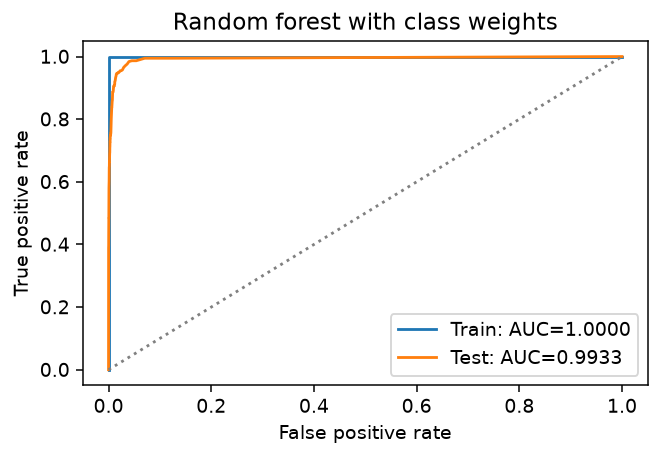

OOB error: 0.00767


In [9]:
weighted_forest = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", class_weight="balanced_subsample",
    oob_score=True, random_state=552, n_jobs=4
)
weighted_forest.fit(train_filled, y_train)
weighted_results = report_model(weighted_forest, train_filled, test_filled,
                                 "Random forest with class weights")
print("OOB error:", round(1 - weighted_forest.oob_score_, 5))

With class weights, test positive recall changes from 0.728 to 0.589, and AUC changes from 0.9944 to 0.9933. The weighted forest's OOB error is 0.7667%; its test error is 1.0500%. Class weighting did not improve the test results at this threshold.

## 1(e) XGBoost without compensation

The TA confirmed that standard XGBoost with L1 regularization is sufficient ([Piazza 142](https://piazza.com/class/mt7h6ldc1j86hm/post/142)). `reg_alpha` penalizes leaf weights. Five-fold stratified CV selects alpha by mean AUC; classification error is also reported. No class weights or resampling are used here.

,alpha,CV AUC,CV error
0,0.0,0.98835,0.00602
1,0.1,0.98946,0.00598
2,1.0,0.98953,0.00608
3,10.0,0.98963,0.00713
4,100.0,0.98265,0.01125


Selected alpha: 10


Pred neg  Pred pos
Set   Actual                    
Train neg        58963        37
      pos          165       835
Test  neg        15601        24
      pos          105       270

,Error,AUC,Positive recall
Set,,,
Train,0.00337,0.99692,0.835
Test,0.00806,0.99598,0.720


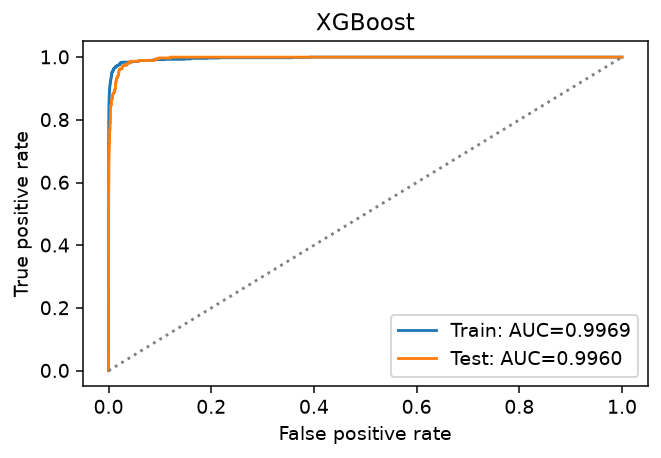

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
alpha_grid = {"model__reg_alpha": [0, 0.1, 1, 10, 100]}
scoring = {"AUC": "roc_auc", "accuracy": "accuracy"}

xgb_settings = dict(n_estimators=200, max_depth=4, learning_rate=0.1,
                    objective="binary:logistic", eval_metric="logloss",
                    tree_method="hist", random_state=552, n_jobs=4)
xgb_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", XGBClassifier(**xgb_settings))
])
xgb_search = GridSearchCV(xgb_model, alpha_grid, scoring=scoring,
                          refit="AUC", cv=cv, n_jobs=1)
xgb_search.fit(X_train, y_train)

xgb_cv = pd.DataFrame({
    "alpha": xgb_search.cv_results_["param_model__reg_alpha"],
    "CV AUC": xgb_search.cv_results_["mean_test_AUC"],
    "CV error": 1 - xgb_search.cv_results_["mean_test_accuracy"]
})
display(xgb_cv)
print("Selected alpha:", xgb_search.best_params_["model__reg_alpha"])
xgb_results = report_model(xgb_search, X_train, X_test, "XGBoost")

At the selected alpha, mean CV error is 0.7133%; test error is 0.8062%.

## 1(f) XGBoost with SMOTE

SMOTE interpolates between nearby positive training observations. Scaling is fitted before SMOTE so large-scale features do not dominate distances. Imputation, scaling, and SMOTE are fitted only within each CV training fold. Validation and test rows keep their original class distributions. Both XGBoost models use the same scaling and parameter grid.
[SMOTE and data leakage](https://imbalanced-learn.org/stable/common_pitfalls.html).

,alpha,CV AUC,CV error
0,0.0,0.98782,0.00988
1,0.1,0.98740,0.00950
2,1.0,0.98733,0.00980
3,10.0,0.98746,0.01053
4,100.0,0.98705,0.02028


Selected alpha: 0
Final resampled training counts: {'neg': 59000, 'pos': 59000}


Pred neg  Pred pos
Set   Actual                    
Train neg        58709       291
      pos           43       957
Test  neg        15500       125
      pos           45       330

,Error,AUC,Positive recall
Set,,,
Train,0.00557,0.99898,0.957
Test,0.01062,0.99416,0.880


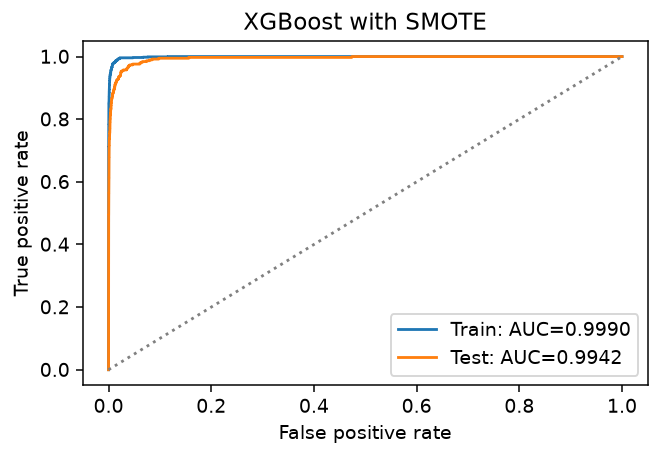

In [11]:
smote_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=552)),
    ("model", XGBClassifier(**xgb_settings))
])
smote_search = GridSearchCV(smote_model, alpha_grid, scoring=scoring,
                            refit="AUC", cv=cv, n_jobs=1)
smote_search.fit(X_train, y_train)

smote_cv = pd.DataFrame({
    "alpha": smote_search.cv_results_["param_model__reg_alpha"],
    "CV AUC": smote_search.cv_results_["mean_test_AUC"],
    "CV error": 1 - smote_search.cv_results_["mean_test_accuracy"]
})
display(smote_cv)
print("Selected alpha:", smote_search.best_params_["model__reg_alpha"])
new_positive = smote_search.best_estimator_.named_steps["smote"].sampling_strategy_[1]
print("Final resampled training counts:", {"neg": int((y_train == 0).sum()),
                                          "pos": int(y_train.sum() + new_positive)})
smote_results = report_model(smote_search, X_train, X_test, "XGBoost with SMOTE")

SMOTE uses all 60,000 original training rows and balances the final training set to 59,000 observations per class. At its selected alpha, mean CV error is 0.9883%, and test error is 1.0625%. Compared with unbalanced XGBoost, test positive recall changes from 0.720 to 0.880, while AUC changes from 0.9960 to 0.9942. Recall improves, but additional false positives increase the error rate. CV selects alpha = 0 here, so the chosen SMOTE model has no L1 penalty.

In [12]:
comparison = pd.DataFrame({
    "Random forest": forest_results.loc["Test"],
    "Weighted forest": weighted_results.loc["Test"],
    "XGBoost": xgb_results.loc["Test"],
    "XGBoost + SMOTE": smote_results.loc["Test"]
}).T
display(comparison)

,Error,AUC,Positive recall
Random forest,0.00756,0.99439,0.72800
Weighted forest,0.01050,0.99331,0.58933
XGBoost,0.00806,0.99598,0.72000
XGBoost + SMOTE,0.01062,0.99416,0.88000


## 2. ISLR 6.6.3

Increasing $s$ relaxes the lasso constraint.

| Part | Choice | Explanation |
|:---|:---|:---|
| (a) Training RSS | iv | It cannot increase because the feasible set expands. It eventually reaches the least-squares minimum. |
| (b) Test RSS | ii | It typically falls as bias decreases, then rises as variance becomes too large. |
| (c) Variance | iii | A less constrained fit is more sensitive to the training sample. |
| (d) Squared bias | iv | Less shrinkage allows a more flexible fit. |
| (e) Irreducible error | v | Changing the model does not change the noise in the data. |

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$ and $s=\beta_1+\beta_2$. The intercept is zero because the variables are centered.

**(a)** For $\lambda>0$, ridge minimizes
$$
\sum_{i=1}^{2}(y_i-x_i\beta_1-x_i\beta_2)^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b)** For fixed $s$, the RSS depends only on $s$, while
$$
\beta_1^2+\beta_2^2=\frac{s^2+(\beta_1-\beta_2)^2}{2}.
$$
The penalty is smallest when $\beta_1=\beta_2=s/2$, so the ridge estimates are equal.

**(c)** Lasso minimizes
$$
\sum_{i=1}^{2}(y_i-x_i\beta_1-x_i\beta_2)^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d)** Since $|\beta_1|+|\beta_2|\ge |s|$, any same-sign split of the optimal sum $s^*$ has the same objective. If $s^*>0$, all pairs $(t,s^*-t)$ with $0\le t\le s^*$ are solutions. If $s^*<0$, use $s^*\le t\le0$. Thus the coefficients need not be unique. If shrinkage gives $s^*=0$ and $\lambda>0$, the solution is $(0,0)$.

## 4. ISLR 8.4.5

Majority vote predicts **Red** because six of the ten trees give a red probability above 0.5.

The average red probability is
$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=0.45.
$$
Averaging probabilities therefore predicts **Green**.

## 5. ISLR 9.7.3

**(a), (b), (d)** The left plot shows the observations, optimal hyperplane, margin lines, and support vectors.

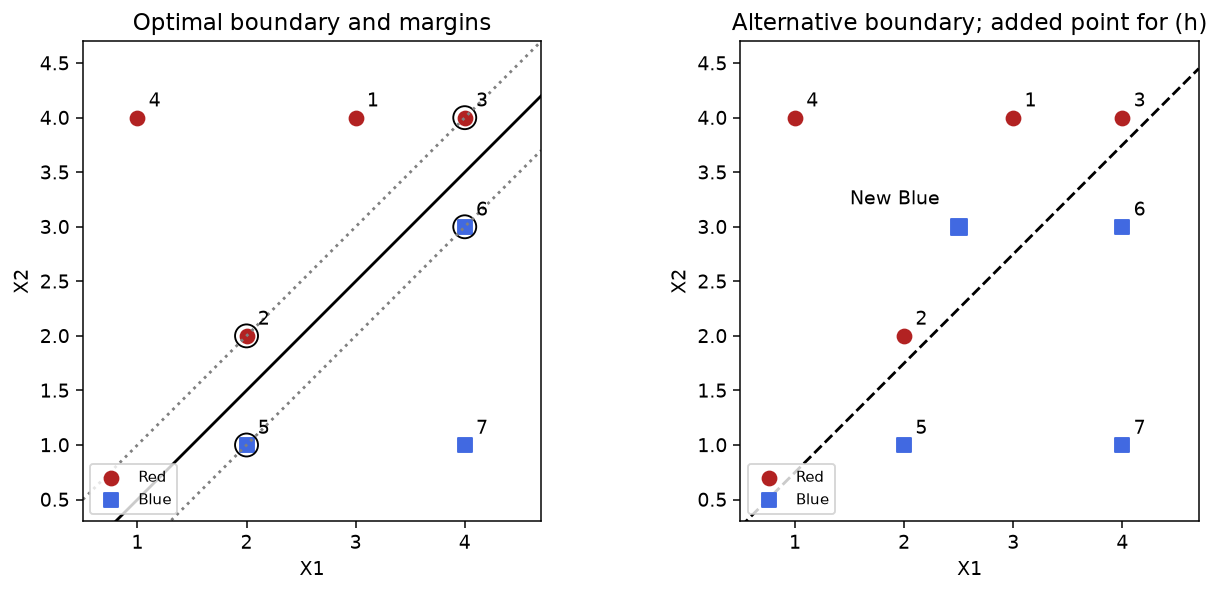

In [13]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4],
                   [2, 1], [4, 3], [4, 1]])
labels = np.array(["Red"] * 4 + ["Blue"] * 3)
x = np.linspace(0.5, 4.7, 150)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax in axes:
    for label, color, marker in [("Red", "firebrick", "o"), ("Blue", "royalblue", "s")]:
        selected = points[labels == label]
        ax.scatter(selected[:, 0], selected[:, 1], c=color, marker=marker,
                   s=55, label=label)
    for i, (x1, x2) in enumerate(points, 1):
        ax.annotate(str(i), (x1, x2), xytext=(6, 6), textcoords="offset points")
    ax.set(xlim=(0.5, 4.7), ylim=(0.3, 4.7), xlabel="X1", ylabel="X2")
    ax.set_aspect("equal")
    ax.legend(loc="lower left", fontsize=8)

axes[0].plot(x, x - 0.5, color="black", label="Optimal boundary")
axes[0].plot(x, x, ":", color="gray")
axes[0].plot(x, x - 1, ":", color="gray")
axes[0].scatter(points[[1, 2, 4, 5], 0], points[[1, 2, 4, 5], 1],
                s=150, facecolors="none", edgecolors="black")
axes[0].set_title("Optimal boundary and margins")
axes[1].plot(x, x - 0.25, "--", color="black")
axes[1].scatter([2.5], [3], c="royalblue", marker="s", s=80)
axes[1].annotate("New Blue", (2.5, 3), xytext=(-58, 12), textcoords="offset points")
axes[1].set_title("Alternative boundary; added point for (h)")
fig.tight_layout()
plt.show()

**(b)** The optimal hyperplane is $X_2=X_1-0.5$.

**(c)** One coefficient choice is $\beta_0=0.5$, $\beta_1=-1$, $\beta_2=1$. Predict Red if $0.5-X_1+X_2>0$, and Blue otherwise. Dividing all coefficients by $\sqrt{2}$ gives a unit-length normal vector.

**(d)** The margin lines are $X_2=X_1$ and $X_2=X_1-1$. Each is $1/(2\sqrt{2})$ from the boundary; the full margin width is $1/\sqrt{2}$.

**(e)** The support vectors are observations **2, 3, 5, and 6**.

**(f)** Observation 7 is strictly outside the margin. A small move that keeps it outside the margin does not change the boundary.

**(g)** $X_2=X_1-0.25$ also separates the original observations, but its closest point is only $0.25/\sqrt{2}$ away, so its margin is smaller.

**(h)** Add a Blue observation at $(2.5,3)$. It lies on the segment joining Red observations 2 and 1, so no hyperplane can strictly separate the two classes.